Initial visualization

First 5 rows:


,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6



Dataset validation:
Dataset dimensions are correct: (319, 39)

Missing values: 0
No missing values found

Patients with gallstones by gender:
Gender
0    68
1    90
Name: count, dtype: int64


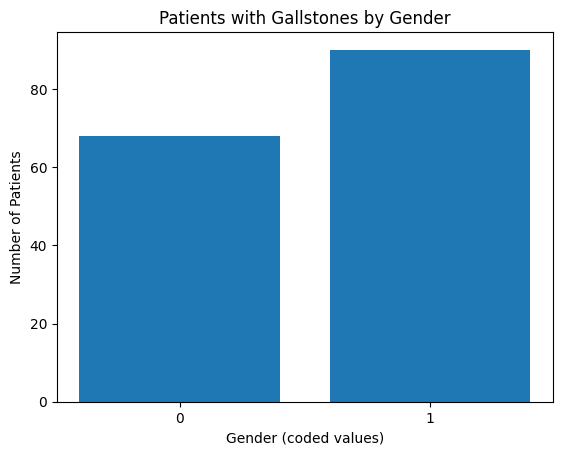

Gallstone Status
0    161
1    158
Name: count, dtype: int64


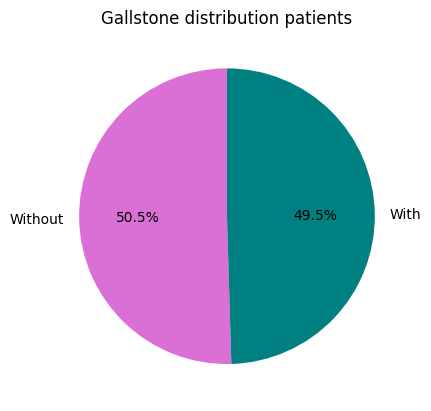

In [ ]:
%pip install -q pandas numpy matplotlib python-calamine

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = 'https://raw.githubusercontent.com/clmns98/csv_file/main/data_gallstone.csv'
df = pd.read_csv(url, delimiter=',')

print("First 5 rows:")
display(df.head())

print("\nDataset validation:")

assert df.shape == (319, 39), "Dataset dimensions are incorrect"
print("Dataset dimensions are correct:", df.shape)

print("\nMissing values:", df.isnull().sum().sum())

if df.isnull().sum().sum() == 0:
    print("No missing values found")
else:
    print("The dataset contains missing values")
    print(df.isnull().sum())

patients = df[df["Gallstone Status"] == 1]

patients_by_gender = patients["Gender"].value_counts().sort_index()

print("\nPatients with gallstones by gender:")
print(patients_by_gender)

plt.bar(patients_by_gender.index.astype(str), patients_by_gender.values)

plt.title("Patients with Gallstones by Gender")
plt.xlabel("Gender (coded values)")
plt.ylabel("Number of Patients")

plt.show()

count_gallstone = df['Gallstone Status'].value_counts()
print(count_gallstone)

plt.pie(count_gallstone, labels=["Without","With"], colors=["#DA70D6", "#008080"], autopct="%1.1f%%", startangle=90)
plt.title("Gallstone distribution patients")
plt.show()


Logistic Regression

   Gallstone Status  Age  Gender  Comorbidity  Coronary Artery Disease (CAD)  \
0                 0   50       0            0                              0   
1                 0   47       0            1                              0   
2                 0   61       0            0                              0   
3                 0   41       0            0                              0   
4                 0   42       0            0                              0   

   Hypothyroidism  Hyperlipidemia  Diabetes Mellitus (DM)  Height  Weight  \
0               0               0                       0     185    92.8   
1               0               0                       0     176    94.5   
2               0               0                       0     171    91.1   
3               0               0                       0     168    67.7   
4               0               0                       0     178    89.6   

   ...  High Density Lipoprotein (HDL)  Triglyceride  \


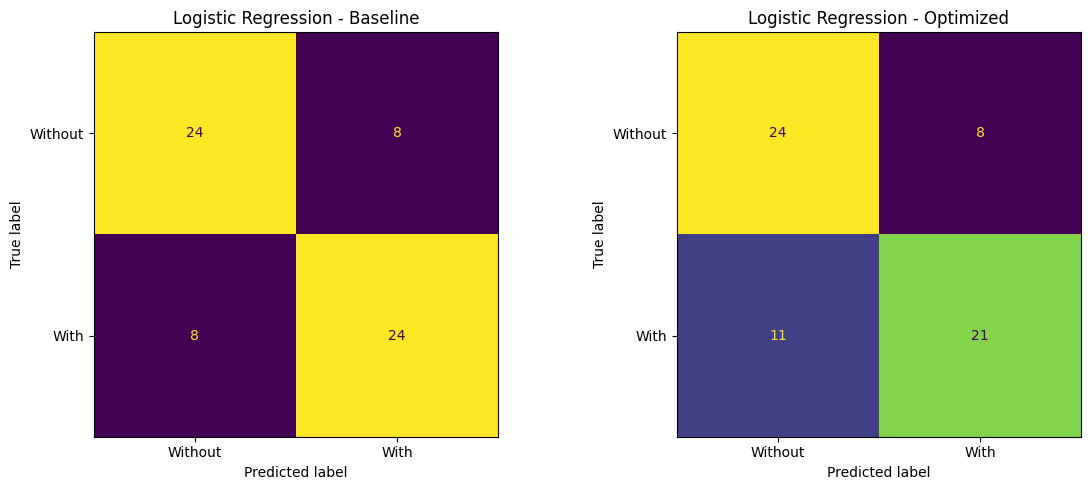

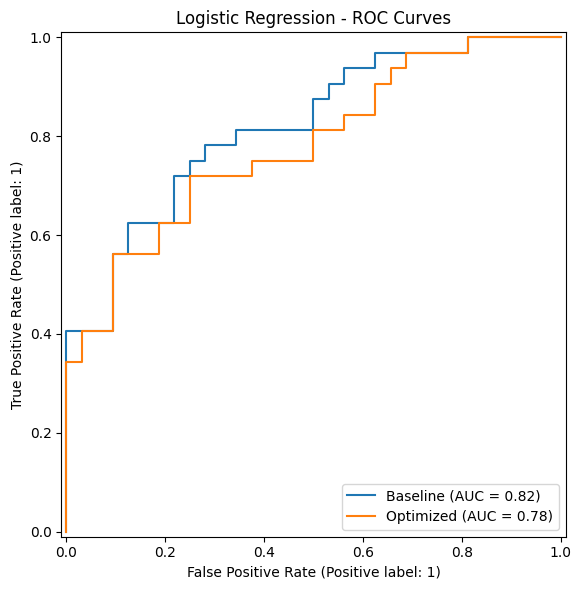


Top 10 Features
                                           Feature  Coefficient  Importance
37                                       Vitamin D    -0.681436    0.681436
35                        C-Reactive Protein (CRP)     0.569424    0.569424
13  Extracellular Fluid/Total Body Water (ECF/TBW)    -0.540119    0.540119
20                                     Obesity (%)    -0.503947    0.503947
6                           Diabetes Mellitus (DM)     0.446511    0.446511
18                                  Bone Mass (BM)    -0.443072    0.443072
5                                   Hyperlipidemia     0.415346    0.415346
28                  High Density Lipoprotein (HDL)     0.325742    0.325742
36                                Hemoglobin (HGB)    -0.297693    0.297693
14                 Total Body Fat Ratio (TBFR) (%)     0.242009    0.242009


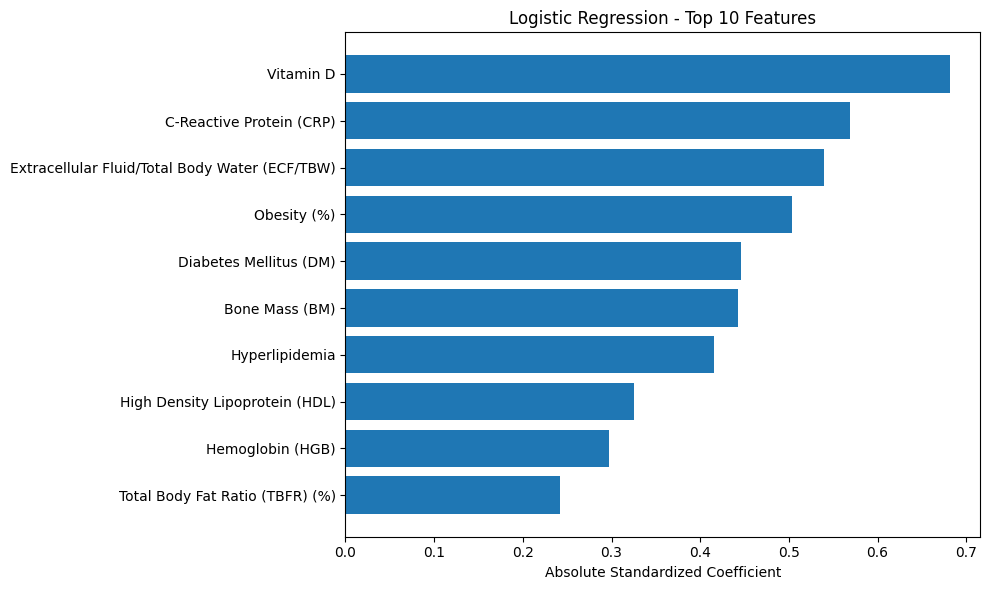

In [ ]:
%pip install -q python-calamine

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay

SEED = 21

url = 'https://raw.githubusercontent.com/clmns98/csv_file/main/data_gallstone.csv'
df = pd.read_csv(url, delimiter=',')

print(df.head())
print(df.shape)

# check if there are any missing or duplicated values
null_values = df.isnull().sum()
duplicated_values = df.duplicated().sum()

if null_values.sum() > 0:
    print("Null values:", null_values[null_values > 0])
else:
    print("No Null values")

if duplicated_values > 0:
    print("Duplicated values:", duplicated_values)
else:
    print("No Duplicated values")

# keep a copy of the original dataset
df_original = df.copy()

# recalculate bmi using weight and height
# we assume that height and weight are valid
df["Body Mass Index (BMI)"] = df["Weight"] / (df["Height"] / 100)**2

# check if the water measurements make sense, 0.21 is the accepted error
water_error = (abs(df["Total Body Water (TBW)"] - df["Extracellular Water (ECW)"] - df["Intracellular Water (ICW)"]) > 0.21) | (df["Total Body Water (TBW)"] > df["Weight"])

# replace the faulty values with the median of the respective column
df.loc[water_error, ["Total Body Water (TBW)", "Extracellular Water (ECW)", "Intracellular Water (ICW)"]] = np.nan

# check if fat mass matches weight and body fat percentage
# accepted error margin of 1, we chose this value arbitrarily
expected_fat = df["Weight"] * df["Total Body Fat Ratio (TBFR) (%)"] / 100
df.loc[abs(df["Total Fat Content (TFC)"] - expected_fat) > 1, "Total Fat Content (TFC)"] = np.nan

# replace suspicious values with nan
# remove every entry of obesity above 300% above zero because it is unlikely that those values are real
df.loc[df["Obesity (%)"] > 300, "Obesity (%)"] = np.nan

# check missing values after cleaning
missing = df.isnull().sum()
print("\nMissing values after cleaning:")
print(missing[missing > 0])

# separate the features and the variable we want to predict
# 0 = without gallstones, 1 = with gallstones
X = df.drop(columns=["Gallstone Status"])
y = df["Gallstone Status"]

# split the data into 80% training and 20% testing
# stratify keeps a similar proportion of both classes
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

# use 5 folds for cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# fill missing values with the median and scale the features
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=SEED))
])

# train the model before tuning
baseline = pipeline
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)
baseline_probabilities = baseline.predict_proba(X_test)[:, 1]

# parameters we want to try
# smaller c means stronger regularization
# solver is the algorithm used to fit the model
param_grid = {
    "model__C": [0.001, 0.1, 1, 10, 100],
    "model__solver": ["lbfgs", "liblinear"]
}

# find the best combination based on f1
grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)

model = grid.best_estimator_
best_lr = model

print("\nBest parameters:", grid.best_params_)
print("Best CV F1:", grid.best_score_)

# make predictions with the optimized model
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)

# get the probability of having gallstones
calculus_probabilities = probabilities[:, 1]

# see how the predictions compare to the actual values
patient_comparison = pd.DataFrame({
    "Real": y_test.values,
    "Prediction": predictions,
    "Gallstone Probability": calculus_probabilities
})

print("\nActual vs Predicted")
print(patient_comparison.head(10))

# compare the results before and after tuning
results_lr = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Version": "Baseline",
        "Accuracy": accuracy_score(y_test, baseline_predictions),
        "Precision": precision_score(y_test, baseline_predictions, zero_division=0),
        "Recall": recall_score(y_test, baseline_predictions, zero_division=0),
        "F1": f1_score(y_test, baseline_predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, baseline_probabilities)
    },
    {
        "Model": "Logistic Regression",
        "Version": "Optimized",
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, calculus_probabilities)
    }
])

# save this score to compare the models later
cv_lr = grid.best_score_

print("\nLogistic Regression - Baseline vs Optimized")
print(results_lr.round(4).to_string(index=False))

# confusion matrices for both versions
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(y_test, baseline_predictions, display_labels=["Without", "With"], ax=axes[0], colorbar=False)
axes[0].set_title("Logistic Regression - Baseline")

ConfusionMatrixDisplay.from_predictions(y_test, predictions, display_labels=["Without", "With"], ax=axes[1], colorbar=False)
axes[1].set_title("Logistic Regression - Optimized")

plt.tight_layout()
plt.show()

# compare the roc curves
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(y_test, baseline_probabilities, name="Baseline", ax=ax)
RocCurveDisplay.from_predictions(y_test, calculus_probabilities, name="Optimized", ax=ax)

plt.title("Logistic Regression - ROC Curves")
plt.tight_layout()
plt.show()

# get the coefficients from the optimized model
logistic_model = model.named_steps["model"]
coefficients = logistic_model.coef_[0]

# use absolute values to see which features have more weight
# keep the original signs to see the direction of the relationship
importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": coefficients,
    "Importance": np.abs(coefficients)
})

importance = importance.sort_values(by="Importance", ascending=False)
importance_lr = importance.copy()

print("\nTop 10 Features")
print(importance.head(10))

# plot the 10 most important features
top_10 = importance.head(10)

plt.figure(figsize=(10, 6))
plt.barh(top_10["Feature"], top_10["Importance"])
plt.gca().invert_yaxis()
plt.xlabel("Absolute Standardized Coefficient")
plt.title("Logistic Regression - Top 10 Features")
plt.tight_layout()
plt.show()

Random Forest

   Gallstone Status  Age  Gender  Comorbidity  Coronary Artery Disease (CAD)  \
0                 0   50       0            0                              0   
1                 0   47       0            1                              0   
2                 0   61       0            0                              0   
3                 0   41       0            0                              0   
4                 0   42       0            0                              0   

   Hypothyroidism  Hyperlipidemia  Diabetes Mellitus (DM)  Height  Weight  \
0               0               0                       0     185    92.8   
1               0               0                       0     176    94.5   
2               0               0                       0     171    91.1   
3               0               0                       0     168    67.7   
4               0               0                       0     178    89.6   

   ...  High Density Lipoprotein (HDL)  Triglyceride  \


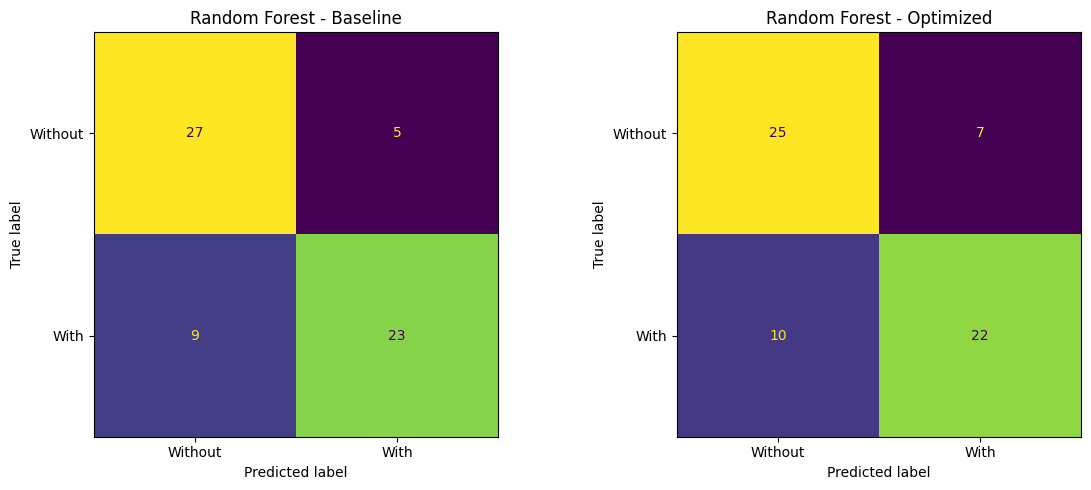

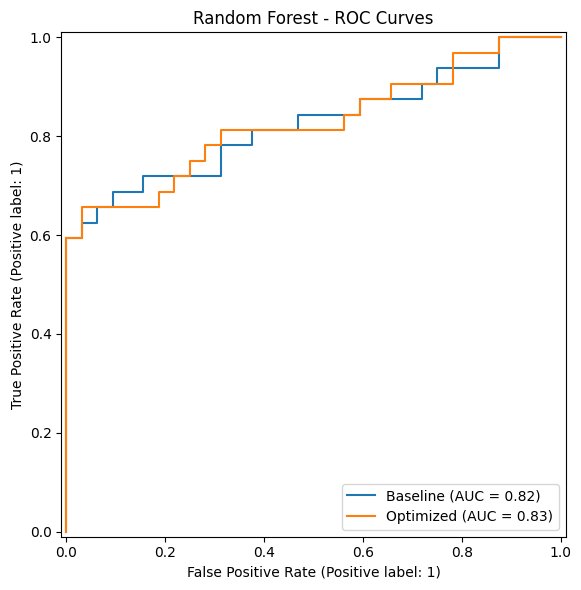

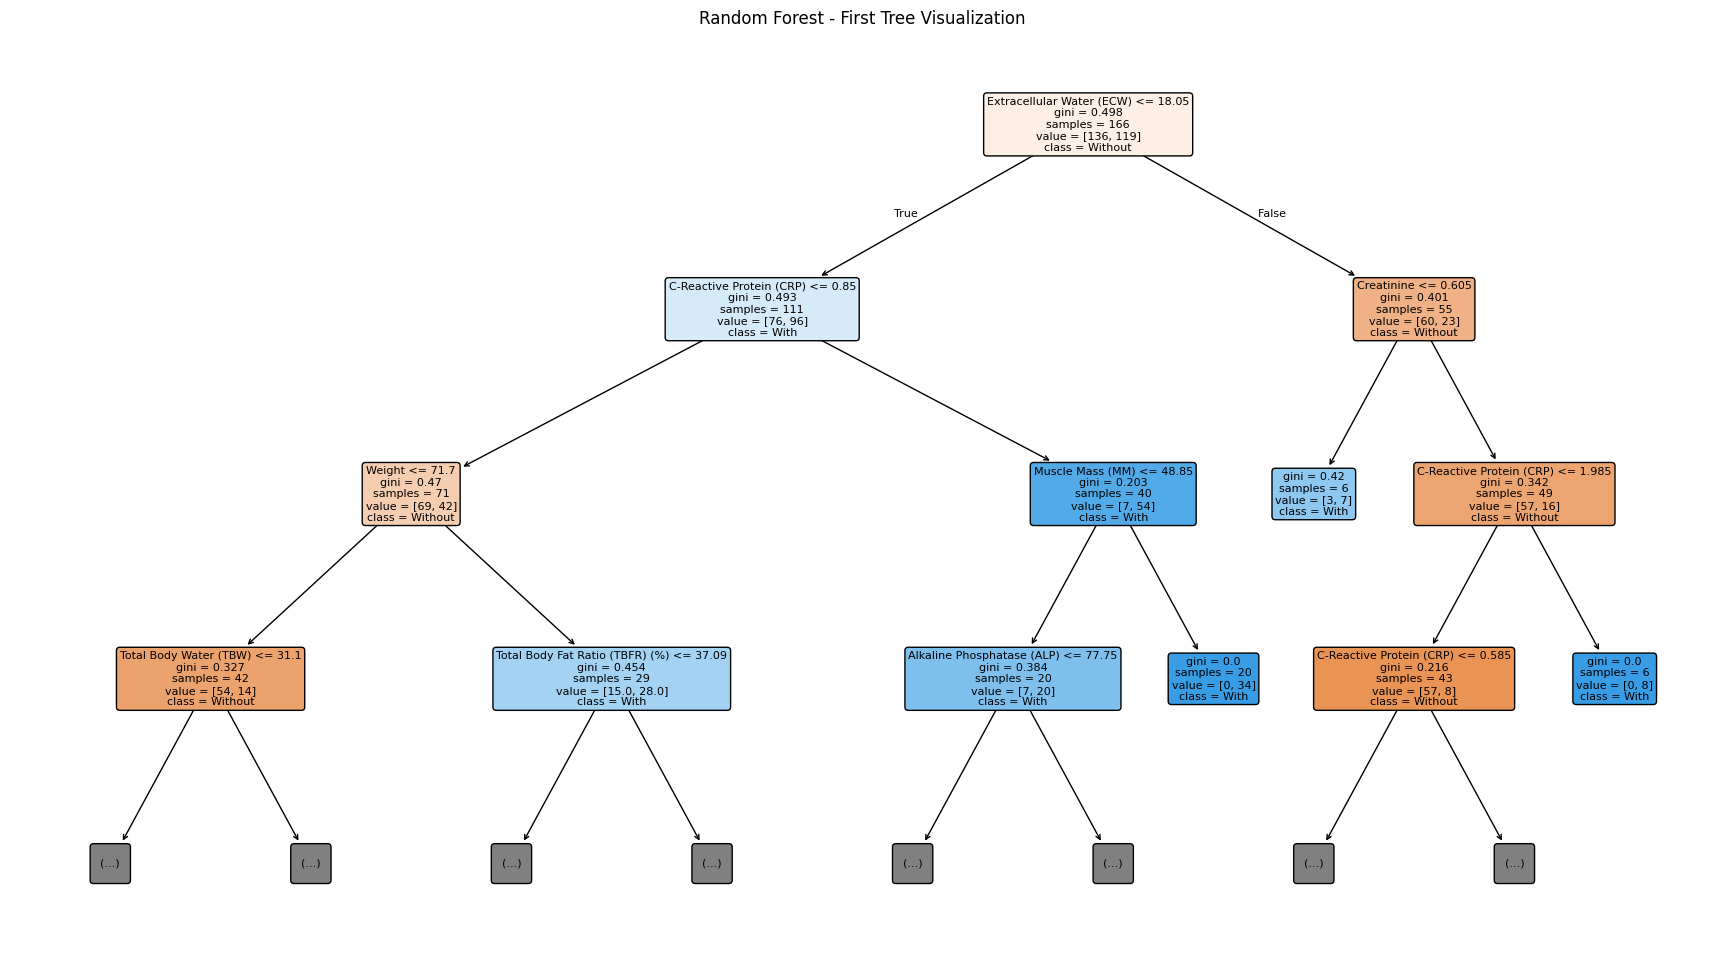


Top 10 Features
                                           Feature  Importance
35                        C-Reactive Protein (CRP)    0.179348
37                                       Vitamin D    0.135971
13  Extracellular Fluid/Total Body Water (ECF/TBW)    0.071839
30                  Aspartat Aminotransferaz (AST)    0.048936
15                              Lean Mass (LM) (%)    0.048319
14                 Total Body Fat Ratio (TBFR) (%)    0.036562
20                                     Obesity (%)    0.026348
11                       Extracellular Water (ECW)    0.026228
12                       Intracellular Water (ICW)    0.025808
18                                  Bone Mass (BM)    0.025497


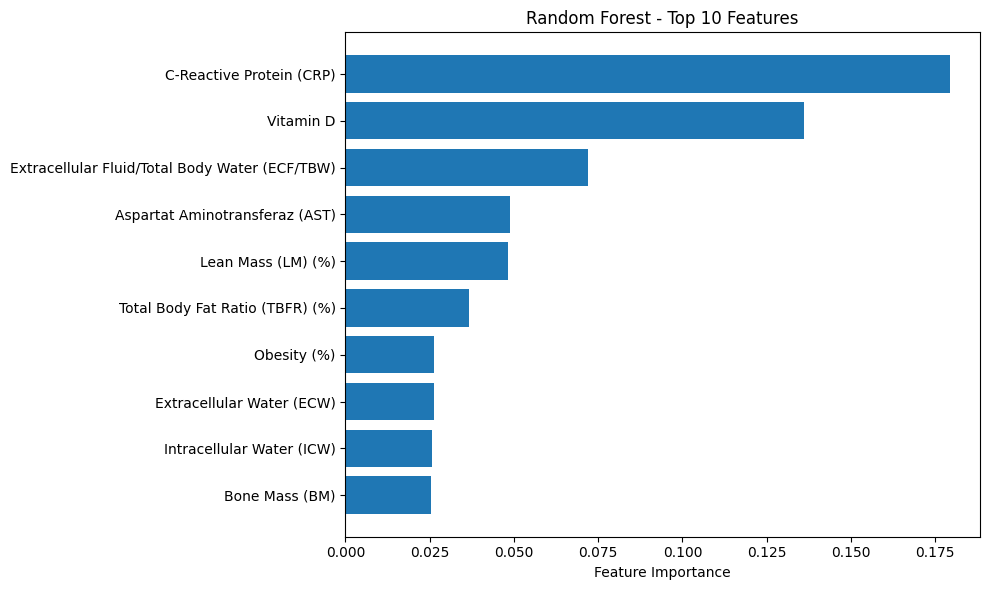

In [ ]:
%pip install -q python-calamine

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import plot_tree
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay

SEED = 21

# df = pd.read_excel("/content/dataset-uci.xlsx", engine="calamine")
url = 'https://raw.githubusercontent.com/clmns98/csv_file/main/data_gallstone.csv'
df = pd.read_csv(url, delimiter=',')

print(df.head())
print(df.shape)

# check if there are any missing or duplicated values
null_values = df.isnull().sum()
duplicated_values = df.duplicated().sum()

if null_values.sum() > 0:
    print("Null values:", null_values[null_values > 0])
else:
    print("No Null values")

if duplicated_values > 0:
    print("Duplicated values:", duplicated_values)
else:
    print("No Duplicated values")

# keep a copy of the original dataset
df_original = df.copy()

# recalculate bmi using weight and height
df["Body Mass Index (BMI)"] = df["Weight"] / (df["Height"] / 100)**2

# check if the water measurements make sense
water_error = (abs(df["Total Body Water (TBW)"] - df["Extracellular Water (ECW)"] - df["Intracellular Water (ICW)"]) > 0.21) | (df["Total Body Water (TBW)"] > df["Weight"])

df.loc[water_error, ["Total Body Water (TBW)", "Extracellular Water (ECW)", "Intracellular Water (ICW)"]] = np.nan

# check if fat mass matches weight and body fat percentage
expected_fat = df["Weight"] * df["Total Body Fat Ratio (TBFR) (%)"] / 100
df.loc[abs(df["Total Fat Content (TFC)"] - expected_fat) > 1, "Total Fat Content (TFC)"] = np.nan

# replace suspicious values with nan
df.loc[df["Obesity (%)"] > 300, "Obesity (%)"] = np.nan

# check missing values after cleaning
missing = df.isnull().sum()
print("\nMissing values after cleaning:")
print(missing[missing > 0])

# separate the features and the target
# 0 = without gallstones, 1 = with gallstones
X = df.drop(columns=["Gallstone Status"])
y = df["Gallstone Status"]

# split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

# use 5 folds for cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# fill missing values with the median
# start with 100 trees and a maximum depth of 4
# no need to scale the features for random forest
forest = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(n_estimators=100, max_depth=4, random_state=SEED, n_jobs=1))
])

# train the model before tuning
baseline = forest
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)
baseline_probabilities = baseline.predict_proba(X_test)[:, 1]

# parameters we want to try
# n_estimators is the number of trees
# max_depth controls how deep each tree can grow
# min_samples_split is the minimum number of samples to split a node
# min_samples_leaf is the minimum number of samples in a leaf
param_grid = {
    "model__n_estimators": [50, 100, 200],
    "model__max_depth": [3, 5, 10, None],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 3, 5]
}

# find the best combination based on f1
grid = GridSearchCV(forest, param_grid, cv=cv, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)

model = grid.best_estimator_
best_rf = model

print("\nBest parameters:", grid.best_params_)
print("Best CV F1:", grid.best_score_)

# make predictions with the optimized model
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)

# get the probability of having gallstones
calculus_probabilities = probabilities[:, 1]

# compare the actual values with the predictions
patient_comparison = pd.DataFrame({
    "Real": y_test.values,
    "Prediction": predictions,
    "Gallstone Probability": calculus_probabilities
})

print("\nActual vs Predicted")
print(patient_comparison.head(10))

# see if tuning improved the results
results_rf = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Version": "Baseline",
        "Accuracy": accuracy_score(y_test, baseline_predictions),
        "Precision": precision_score(y_test, baseline_predictions, zero_division=0),
        "Recall": recall_score(y_test, baseline_predictions, zero_division=0),
        "F1": f1_score(y_test, baseline_predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, baseline_probabilities)
    },
    {
        "Model": "Random Forest",
        "Version": "Optimized",
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, calculus_probabilities)
    }
])

# save this score to compare the models later
cv_rf = grid.best_score_

print("\nRandom Forest - Baseline vs Optimized")
print(results_rf.round(4).to_string(index=False))

# confusion matrices for both versions
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(y_test, baseline_predictions, display_labels=["Without", "With"], ax=axes[0], colorbar=False)
axes[0].set_title("Random Forest - Baseline")

ConfusionMatrixDisplay.from_predictions(y_test, predictions, display_labels=["Without", "With"], ax=axes[1], colorbar=False)
axes[1].set_title("Random Forest - Optimized")

plt.tight_layout()
plt.show()

# compare the roc curves
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(y_test, baseline_probabilities, name="Baseline", ax=ax)
RocCurveDisplay.from_predictions(y_test, calculus_probabilities, name="Optimized", ax=ax)

plt.title("Random Forest - ROC Curves")
plt.tight_layout()
plt.show()

# get the random forest from the pipeline
forest_model = model.named_steps["model"]

# pick the first tree from the optimized forest as an example
# show only the first few levels so the plot is easier to read
first_tree = forest_model.estimators_[0]

plt.figure(figsize=(22, 12))
plot_tree(first_tree, feature_names=X.columns, class_names=["Without", "With"], filled=True, rounded=True, max_depth=3, fontsize=8)
plt.title("Random Forest - First Tree Visualization")
plt.show()

# see which features helped the most when splitting the data
# importance is based on the reduction in impurity across the trees
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": forest_model.feature_importances_
})

importance = importance.sort_values(by="Importance", ascending=False)
importance_rf = importance.copy()

print("\nTop 10 Features")
print(importance.head(10))

# plot the 10 most important features
top_10 = importance.head(10)

plt.figure(figsize=(10, 6))
plt.barh(top_10["Feature"], top_10["Importance"])
plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.title("Random Forest - Top 10 Features")
plt.tight_layout()
plt.show()

K-Nearest Neighbors

   Gallstone Status  Age  Gender  Comorbidity  Coronary Artery Disease (CAD)  \
0                 0   50       0            0                              0   
1                 0   47       0            1                              0   
2                 0   61       0            0                              0   
3                 0   41       0            0                              0   
4                 0   42       0            0                              0   

   Hypothyroidism  Hyperlipidemia  Diabetes Mellitus (DM)  Height  Weight  \
0               0               0                       0     185    92.8   
1               0               0                       0     176    94.5   
2               0               0                       0     171    91.1   
3               0               0                       0     168    67.7   
4               0               0                       0     178    89.6   

   ...  High Density Lipoprotein (HDL)  Triglyceride  \


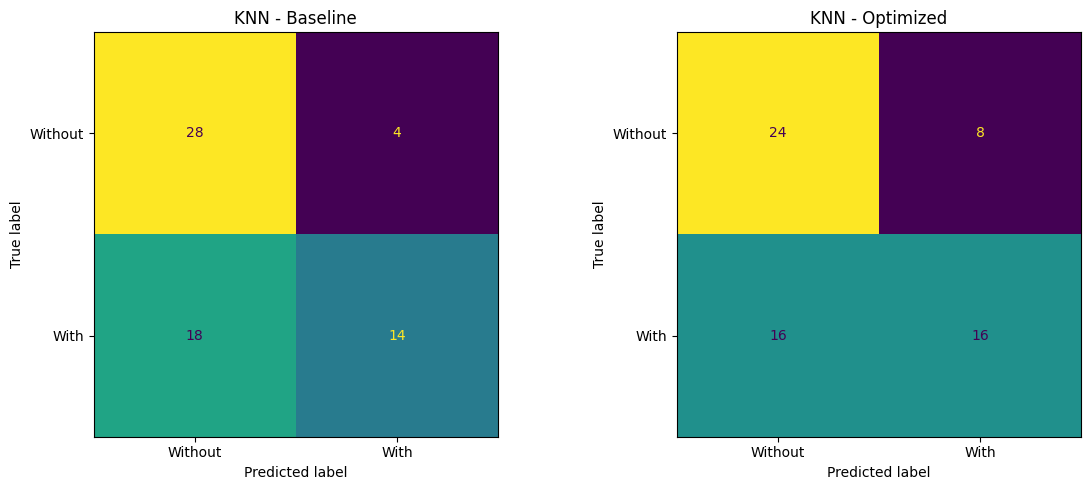

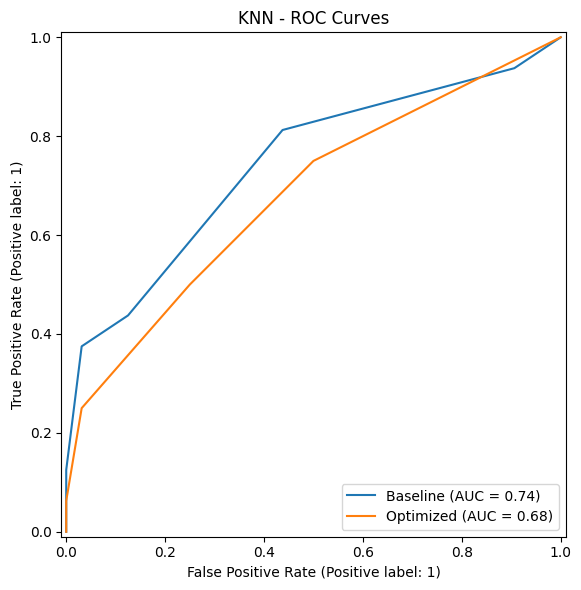

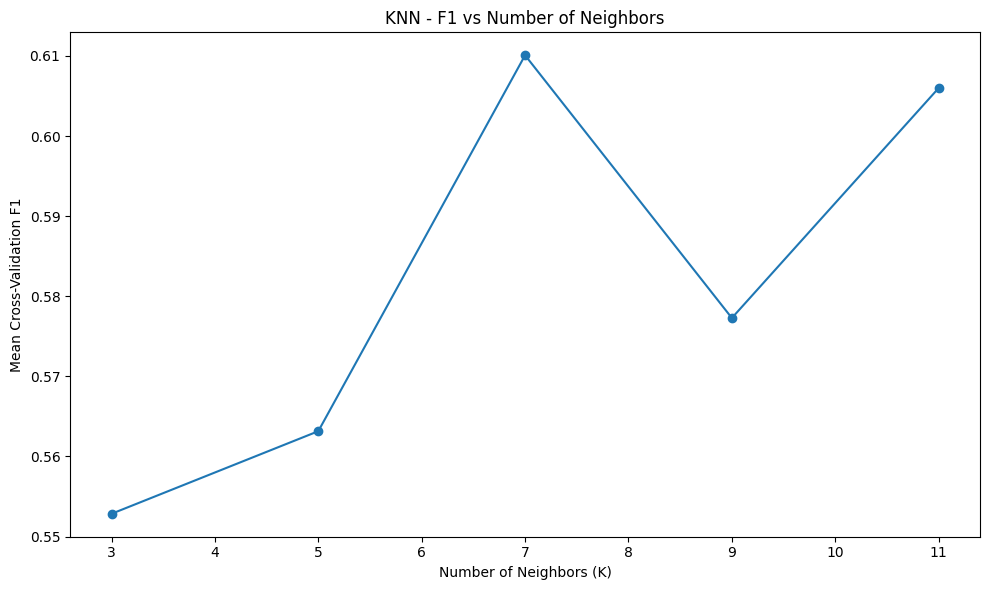


Top 10 Features
                           Feature  Importance
25                         Glucose    0.063217
17       Visceral Fat Rating (VFR)    0.062548
6           Diabetes Mellitus (DM)    0.046789
30  Aspartat Aminotransferaz (AST)    0.045353
24  Hepatic Fat Accumulation (HFA)    0.041150
2                      Comorbidity    0.036248
37                       Vitamin D    0.030187
19                Muscle Mass (MM)    0.029728
3    Coronary Artery Disease (CAD)    0.025092
21         Total Fat Content (TFC)    0.021351


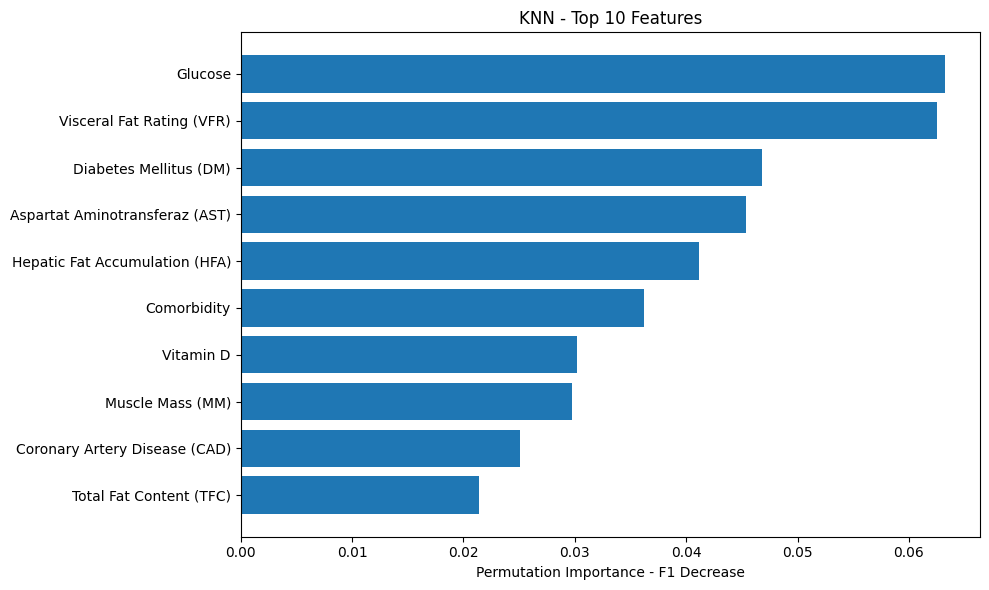

In [ ]:
%pip install -q python-calamine

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay

SEED = 21

# df = pd.read_excel("/content/dataset-uci.xlsx", engine="calamine")
url = 'https://raw.githubusercontent.com/clmns98/csv_file/main/data_gallstone.csv'
df = pd.read_csv(url, delimiter=',')

print(df.head())
print(df.shape)

# check if there are any missing or duplicated values
null_values = df.isnull().sum()
duplicated_values = df.duplicated().sum()

if null_values.sum() > 0:
    print("Null values:", null_values[null_values > 0])
else:
    print("No Null values")

if duplicated_values > 0:
    print("Duplicated values:", duplicated_values)
else:
    print("No Duplicated values")

# keep a copy of the original dataset
df_original = df.copy()

# recalculate bmi using weight and height
df["Body Mass Index (BMI)"] = df["Weight"] / (df["Height"] / 100)**2

# check if the water measurements make sense
water_error = (abs(df["Total Body Water (TBW)"] - df["Extracellular Water (ECW)"] - df["Intracellular Water (ICW)"]) > 0.21) | (df["Total Body Water (TBW)"] > df["Weight"])

df.loc[water_error, ["Total Body Water (TBW)", "Extracellular Water (ECW)", "Intracellular Water (ICW)"]] = np.nan

# check if fat mass matches weight and body fat percentage
expected_fat = df["Weight"] * df["Total Body Fat Ratio (TBFR) (%)"] / 100
df.loc[abs(df["Total Fat Content (TFC)"] - expected_fat) > 1, "Total Fat Content (TFC)"] = np.nan

# replace suspicious values with nan
df.loc[df["Obesity (%)"] > 300, "Obesity (%)"] = np.nan

# check missing values after cleaning
missing = df.isnull().sum()
print("\nMissing values after cleaning:")
print(missing[missing > 0])

# separate the features and the target
# 0 = without gallstones, 1 = with gallstones
X = df.drop(columns=["Gallstone Status"])
y = df["Gallstone Status"]

# split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

# use 5 folds for cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# fill missing values with the median
# scale the data since knn works with distances
# start with 5 neighbors
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

# train the model before tuning
baseline = pipeline
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)
baseline_probabilities = baseline.predict_proba(X_test)[:, 1]

# parameters we want to try
# n_neighbors is the number of neighbors used
# uniform gives all neighbors the same weight
# distance gives closer neighbors more weight
# p=1 is manhattan distance and p=2 is euclidean distance
param_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}

# find the best combination based on f1
# use a pipeline to avoid data leakage when filling and scaling
grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)

model = grid.best_estimator_
best_knn = model

print("\nBest parameters:", grid.best_params_)
print("Best CV F1:", grid.best_score_)

# make predictions with the optimized model
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)

# get the probability of having gallstones
calculus_probabilities = probabilities[:, 1]

# compare the actual values with the predictions
patient_comparison = pd.DataFrame({
    "Real": y_test.values,
    "Prediction": predictions,
    "Gallstone Probability": calculus_probabilities
})

print("\nActual vs Predicted")
print(patient_comparison.head(10))

# compare the results before and after tuning
results_knn = pd.DataFrame([
    {
        "Model": "KNN",
        "Version": "Baseline",
        "Accuracy": accuracy_score(y_test, baseline_predictions),
        "Precision": precision_score(y_test, baseline_predictions, zero_division=0),
        "Recall": recall_score(y_test, baseline_predictions, zero_division=0),
        "F1": f1_score(y_test, baseline_predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, baseline_probabilities)
    },
    {
        "Model": "KNN",
        "Version": "Optimized",
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, calculus_probabilities)
    }
])

# save this score to compare the models later
cv_knn = grid.best_score_

print("\nKNN - Baseline vs Optimized")
print(results_knn.round(4).to_string(index=False))

# confusion matrices for both versions
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(y_test, baseline_predictions, display_labels=["Without", "With"], ax=axes[0], colorbar=False)
axes[0].set_title("KNN - Baseline")

ConfusionMatrixDisplay.from_predictions(y_test, predictions, display_labels=["Without", "With"], ax=axes[1], colorbar=False)
axes[1].set_title("KNN - Optimized")

plt.tight_layout()
plt.show()

# compare the roc curves
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(y_test, baseline_probabilities, name="Baseline", ax=ax)
RocCurveDisplay.from_predictions(y_test, calculus_probabilities, name="Optimized", ax=ax)

plt.title("KNN - ROC Curves")
plt.tight_layout()
plt.show()

# see how the number of neighbors affects f1
grid_results = pd.DataFrame(grid.cv_results_)

# keep the weights and distance the same so we only compare k
k_results = grid_results[(grid_results["param_model__weights"] == "uniform") & (grid_results["param_model__p"] == 2)].copy()

k_results = k_results.sort_values(by="param_model__n_neighbors")

plt.figure(figsize=(10, 6))
plt.plot(k_results["param_model__n_neighbors"].astype(int), k_results["mean_test_score"], marker="o")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean Cross-Validation F1")
plt.title("KNN - F1 vs Number of Neighbors")
plt.tight_layout()
plt.show()

# knn doesn't have its own feature importance
# shuffle each feature and measure the change in f1
# repeat this 10 times for each feature and take the average
permutation = permutation_importance(model, X_test, y_test, scoring="f1", n_repeats=10, random_state=SEED)

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": permutation.importances_mean
})

importance = importance.sort_values(by="Importance", ascending=False)
importance_knn = importance.copy()

print("\nTop 10 Features")
print(importance.head(10))

# plot the 10 most important features
top_10 = importance.head(10)

plt.figure(figsize=(10, 6))
plt.barh(top_10["Feature"], top_10["Importance"])
plt.gca().invert_yaxis()
plt.xlabel("Permutation Importance - F1 Decrease")
plt.title("KNN - Top 10 Features")
plt.tight_layout()
plt.show()

Validation


All Models - Baseline vs Optimized
              Model   Version  Accuracy  Precision  Recall     F1  ROC-AUC
Logistic Regression  Baseline    0.7500     0.7500  0.7500 0.7500   0.8193
Logistic Regression Optimized    0.7031     0.7241  0.6562 0.6885   0.7812
      Random Forest  Baseline    0.7812     0.8214  0.7188 0.7667   0.8242
      Random Forest Optimized    0.7344     0.7586  0.6875 0.7213   0.8262
                KNN  Baseline    0.6562     0.7778  0.4375 0.5600   0.7422
                KNN Optimized    0.6250     0.6667  0.5000 0.5714   0.6807

Best Model: Random Forest
Cross-Validation F1: 0.7883

Best Model - Test Results
        Model   Version  Accuracy  Precision  Recall     F1  ROC-AUC
Random Forest Optimized    0.7344     0.7586  0.6875 0.7213   0.8262


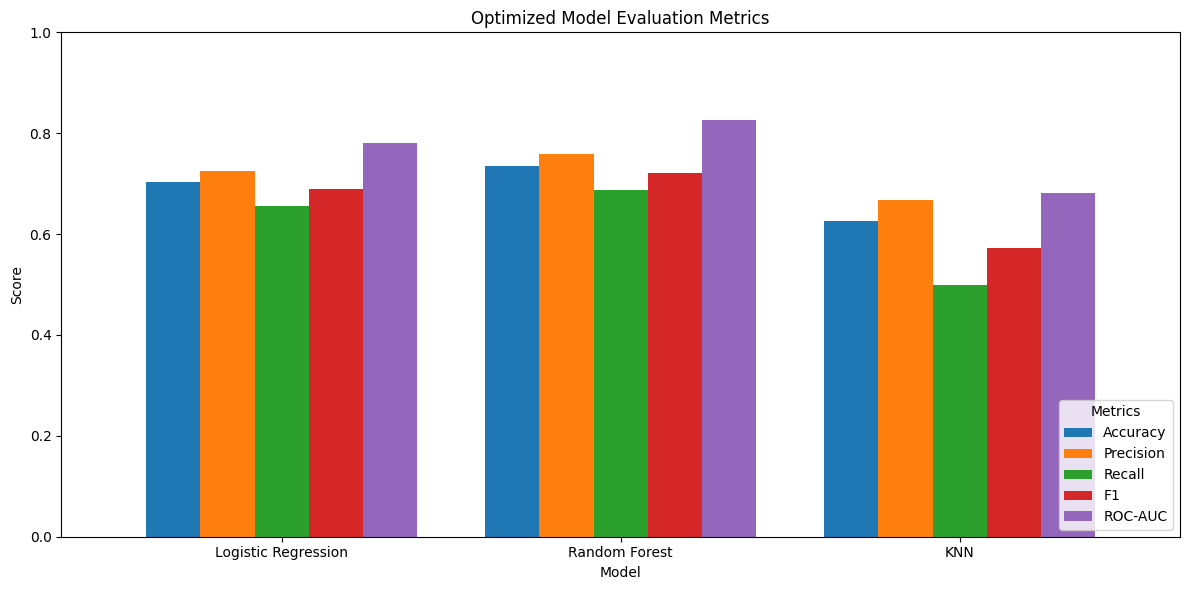

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# put all the model results together
all_results = pd.concat([results_lr, results_rf, results_knn], ignore_index=True)

print("\nAll Models - Baseline vs Optimized")
print(all_results.round(4).to_string(index=False))

# keep only the optimized models
optimized_results = all_results[all_results["Version"] == "Optimized"].copy()

# get the cross-validation f1 score from each model
cv_results = {
    "Logistic Regression": cv_lr,
    "Random Forest": cv_rf,
    "KNN": cv_knn
}

# pick the model with the highest cross-validation f1
best_model_name = max(cv_results, key=cv_results.get)
best_model_results = optimized_results[optimized_results["Model"] == best_model_name]

# show the best model and its test results
print("\nBest Model:", best_model_name)
print("Cross-Validation F1:", round(cv_results[best_model_name], 4))

print("\nBest Model - Test Results")
print(best_model_results.round(4).to_string(index=False))

# metrics we want to compare
metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]

# plot the results of the three optimized models
optimized_results.set_index("Model")[metrics].plot(kind="bar", figsize=(12, 6), width=0.8, rot=0)

plt.title("Optimized Model Evaluation Metrics")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(title="Metrics", loc="lower right")
plt.tight_layout()
plt.show()